# [17.2] Induction Heads in Hand-Built Circuits (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter17_training_dynamics/exercises/part2_induction_head_emergence/17.2_Induction_Heads_in_Hand-Built_Circuits_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter17_training_dynamics/exercises/part2_induction_head_emergence/17.2_Induction_Heads_in_Hand-Built_Circuits_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-12.png" width="350">

# Introduction

By the end of this notebook, you will have shown that a two-stage attention circuit can copy a repeated token continuation, using token-level loss and a previous-token ablation alongside a wrong-value control.

`A B C D A B C` — what comes next? A head that attends from the final `C` to the **first `D`** can copy the answer. Merely attending to the earlier `C` copies the wrong token. How could a dot-product attention head find the token *after* a match?

In a two-layer attention-only transformer, an earlier previous-token head can write the previous token into each position. A later head can match its current token against that stored key: at the first `D`, the stored previous token is `C`. You will implement this circuit and make it fail in two different ways.

The checkpoint coordinate in this notebook is an **explicitly chosen circuit strength**, not optimizer time. These are deterministic constructed checkpoints, not a measured emergence trajectory. This distinction lets us test mechanism and measurement without inventing training evidence. A native study also calls for a trained two-layer model, phase-change analysis, training-time freezing, and public Pythia checkpoints; those native experiments remain pending.

Prerequisites: [1.2] induction heads, attention matrix axes, NumPy matrix multiplication, and cross-entropy. Budget: roughly 90–120 minutes; the reference computation takes seconds on CPU.

## Content & Learning Objectives

### 1️⃣ Build a copying circuit

> ##### Learning Objectives
>
> - Construct previous-token keys and causal prefix-matching attention; check the exact token positions.

### 2️⃣ Measure more than an attention stripe

> ##### Learning Objectives
>
> - Implement prefix matching, next-token loss, in-context improvement and a weight-composition diagnostic.

### 3️⃣ Intervene on the mechanism

> ##### Learning Objectives
>
> - Compare a controlled family of fixed circuits with previous-token ablation and a wrong-value control.

### 4️⃣ From fixed circuits to training checkpoints

> ##### Learning Objectives
>
> - Design an honest phase-change analysis and edit the repeated-token organism.

## Setup code

Use the repository environment. This study edition needs only NumPy and Matplotlib, runs on CPU, and downloads nothing.

In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
chapter = "chapter17_training_dynamics"
section = "part2_induction_head_emergence"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))
import part2_induction_head_emergence.tests as tests
import part2_induction_head_emergence.utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Build a copying circuit

> ##### Learning Objectives
>
> - Construct previous-token keys and causal prefix-matching attention; check the exact token positions.

At position $i$, an attention row indexes source positions $j$. A causal model allows $j\leq i$. First we make a clean periodic sequence with no accidental token duplicates inside one period. This isolates prefix matching from token-frequency effects. In a natural-language experiment, repeated tokens and beginning-of-sequence handling require additional controls.

We represent tokens as rows of the identity matrix, $E\in\mathbb R^{T\times V}$. The previous-token head has $P_{ij}=1$ when $j=i-1$, and zero otherwise. Row zero is deliberately all zero: no invented previous token. Its output $K=PE$ stores the previous token at each source position.

### Exercise - implement `repeat_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a one-dimensional integer sequence with `repeats` copies of `0,...,period-1`. Require period >=2 and repeats >=2. This controlled fixture removes accidental within-block repeats.

In [ ]:
def repeat_tokens(period, repeats=3):
    raise NotImplementedError()


tests.test_repeat_tokens(repeat_tokens)

<details><summary>Hint</summary>

Use `tile`, not `repeat`; these place copies along different axes.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">repeat_tokens(3, 2) = [0, 1, 2, 0, 1, 2]</pre>

</details>


<details><summary>Solution</summary>

```python
def repeat_tokens(period, repeats=3):
    if period < 2 or repeats < 2:
        raise ValueError("Need a nontrivial repeated block")
    return np.tile(np.arange(period), repeats)
```
</details>

### Exercise - implement `previous_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Build a [T,T] previous-token attention matrix. Row zero has no source and sums to zero; every other row sums to one.

In [ ]:
def previous_attention(length):
    raise NotImplementedError()


tests.test_previous_attention(previous_attention)

<details><summary>Hint</summary>

Think of which diagonal corresponds to source = destination - 1.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Rows 1–3 copy positions 0–2; row 0 is zero.</pre>

</details>


<details><summary>Solution</summary>

```python
def previous_attention(length):
    return np.eye(length, k=-1)
```
</details>

### Exercise - implement `prefix_keys`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Given token IDs [T], return [T,V] previous-token keys. `strength=0` ablates this head; `strength=1` gives exact token keys. Do not shift with wraparound.

In [ ]:
def prefix_keys(tokens, vocab, strength=1.0):
    raise NotImplementedError()


tests.test_prefix_keys(prefix_keys)

<details><summary>Hint</summary>

Apply the previous-token attention to one-hot value vectors.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">prefix_keys([2,0,1],3) has rows zero, e₂, e₀.</pre>

</details>


<details><summary>Solution</summary>

```python
def prefix_keys(tokens, vocab, strength=1.0):
    one_hot = np.eye(vocab)[tokens]
    return strength * previous_attention(len(tokens)) @ one_hot
```
</details>

### Exercise - implement `causal_softmax`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Normalize square attention scores [T,T] along the source axis, with all strictly future entries exactly zero. Use stable exponentials.

In [ ]:
def causal_softmax(scores):
    raise NotImplementedError()


tests.test_causal_softmax(causal_softmax)

<details><summary>Hint</summary>

Mask before finding the maximum, and normalize rows.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Zero scores give causal-uniform rows [1], [1/2,1/2], [1/3,1/3,1/3].</pre>

</details>


<details><summary>Solution</summary>

```python
def causal_softmax(scores):
    mask = np.tril(np.ones_like(scores, dtype=bool))
    x = np.where(mask, scores, -np.inf)
    x = np.exp(x - x.max(axis=-1, keepdims=True))
    return x / x.sum(axis=-1, keepdims=True)
```
</details>

In [ ]:
small_tokens=repeat_tokens(3,2)
small_keys=prefix_keys(small_tokens,3)
print("position token previous-key-token ablated-key-norm")
for i,(token,key) in enumerate(zip(small_tokens,small_keys)):
    previous=int(key.argmax()) if key.sum() else "none"
    print(i,int(token),previous,0.)

<details><summary>Help - why is row zero different?</summary>

For tokens 0,1,2,0,1,2 the stored previous-token IDs are none,0,1,2,0,1. The ablated-key norm is zero everywhere. A circular shift would store the final token at row zero and leak information from beyond the prefix.

</details>

## Summary of 1️⃣

You can now construct keys without leaking a future token. A good-looking stripe can still copy the wrong value, so our next measurements include the actual token prediction.

# 2️⃣ Measure more than an attention stripe

> ##### Learning Objectives
>
> - Implement prefix matching, next-token loss, in-context improvement and a weight-composition diagnostic.

Queries are current one-hot tokens. Scores are $S=\beta EK^\top$, with inverse temperature $\beta$. The first matching key occurs at the position **after** the previous occurrence of the current token. We evaluate offsets 0 through p-2 within the first and second blocks, deliberately excluding each block-boundary transition so the early/repeated comparison uses matched within-block offsets. With three repeats, the final token of the second block does have an observed next-token target in the third block; it is excluded by this scoring convention, not because its target is missing. Only the final token of the entire sequence lacks an observed next-token target.

Prefix matching is the mean attention mass at the analytically known source $j=i-p+1$ for period $p$. This is an attention diagnostic, not a causal effect. The copying readout forms vocabulary logits $L=\alpha AE$. Cross-entropy uses the next token, never the current token. Our in-context improvement compares mean early-block loss to repeated-block loss on corresponding offsets. Units are nats/token; positive means lower repeated-context loss.

### Exercise - implement `induction_pattern`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return [T,T] causal attention from current-token queries and previous-token keys. `beta` scales similarity; it is not a learned parameter in this fixture.

In [ ]:
def induction_pattern(tokens, vocab, strength=1.0, beta=12.0):
    raise NotImplementedError()


tests.test_induction_pattern(induction_pattern)

<details><summary>Hint</summary>

The keys are attached to source positions. The query at second A matches the previous-token key stored at first B.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">For [0,1,2,0,1,2], attention[3,1] and attention[4,2] exceed .99.</pre>

</details>


<details><summary>Solution</summary>

```python
def induction_pattern(tokens, vocab, strength=1.0, beta=12.0):
    q = np.eye(vocab)[tokens]
    k = prefix_keys(tokens, vocab, strength)
    return causal_softmax(beta * q @ k.T)
```
</details>

### Exercise - implement `prefix_score`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Average attention at the known induction source over second-block destinations `period ... 2*period-2`. Exclude the final offset of the second block to match the within-block offsets used for the early/repeated loss comparison. In the three-repeat fixture that excluded destination still has an observed target; only the final destination of the entire sequence has no target.

In [ ]:
def prefix_score(attention, period):
    raise NotImplementedError()


tests.test_prefix_score(prefix_score)

<details><summary>Hint</summary>

Use paired advanced indexing, not a Cartesian submatrix.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">A fixture with stripe entries .2 and .8 has prefix score .5.</pre>

</details>


<details><summary>Solution</summary>

```python
def prefix_score(attention, period):
    dest = np.arange(period, 2*period-1)
    return float(attention[dest, dest-period+1].mean())
```
</details>

### Exercise - implement `copy_logits`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return vocabulary logits [T,V] by attending to **current source tokens** as values. A wrong-value control will deliberately rotate these value IDs.

In [ ]:
def copy_logits(attention, tokens, vocab, scale=8.0):
    raise NotImplementedError()


tests.test_copy_logits(copy_logits)

<details><summary>Hint</summary>

Multiply attention by the value one-hots; previous-token keys and current-token values are different objects.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">For source tokens [1,0], attention [.25,.75], scale 4: logits [3,1].</pre>

</details>


<details><summary>Solution</summary>

```python
def copy_logits(attention, tokens, vocab, scale=8.0):
    return scale * attention @ np.eye(vocab)[tokens]
```
</details>

### Exercise - implement `next_token_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute [T-1] next-token negative log probability with stable log-sum-exp. Exclude the final logits row, which has no observed next token.

In [ ]:
def next_token_loss(logits, tokens):
    raise NotImplementedError()


tests.test_next_token_loss(next_token_loss)

<details><summary>Hint</summary>

Each row i is scored against tokens[i+1], with one log-normalizer per row.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Known probabilities .75 and .8 give losses .287682 and .223144 nats.</pre>

</details>


<details><summary>Solution</summary>

```python
def next_token_loss(logits, tokens):
    x = logits[:-1]
    m = x.max(axis=-1)
    log_z = m + np.log(np.exp(x-m[:,None]).sum(axis=-1))
    return log_z - x[np.arange(len(tokens)-1), tokens[1:]]
```
</details>

### Exercise - implement `icl_gain`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compare corresponding offsets in first and second block, excluding each block’s final destination. Return early mean minus repeated mean in nats/token.

In [ ]:
def icl_gain(losses, period):
    raise NotImplementedError()


tests.test_icl_gain(icl_gain)

<details><summary>Hint</summary>

The boundary at period-1 predicts the next block and should not enter this paired-offset comparison.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Loss [3,5,999,1,2,999] with period 3 gives gain 2.5 nats.</pre>

</details>


<details><summary>Solution</summary>

```python
def icl_gain(losses, period):
    return float(losses[:period-1].mean() - losses[period:2*period-1].mean())
```
</details>

In [ ]:
worked_tokens=repeat_tokens(4,3)
worked_attention=induction_pattern(worked_tokens,4)
worked_logits=copy_logits(worked_attention,worked_tokens,4)
wrong_logits=copy_logits(worked_attention,(worked_tokens+1)%4,4)
print("destination current expected clean-top1 wrong-value-top1")
for i in range(4,7):
    print(i,int(worked_tokens[i]),int(worked_tokens[i+1]),int(worked_logits[i].argmax()),int(wrong_logits[i].argmax()))

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">destination current expected clean-top1 wrong-value-top1
4 0 1 1 2
5 1 2 2 3
6 2 3 3 0</pre>

</details>

The attention pattern is identical in both columns. Correct source selection needs the correct value and readout maps to implement copying.

## Summary of 2️⃣

A prefix score asks where the head looks. Next-token loss asks whether its values and readout make that attention useful. Neither metric alone identifies learned emergence.

# 3️⃣ Intervene on the mechanism

> ##### Learning Objectives
>
> - Compare a controlled family of fixed circuits with previous-token ablation and a wrong-value control.

A composition diagnostic should inspect the *path*, not only each matrix norm. For compatible maps $A,B$, use $\|AB\|_F/(\|A\|_F\|B\|_F)$. A high value indicates aligned maps but is neither an induction score nor a proof of behavior. We use a one-hot path where the diagnostic can be checked analytically, then ablate its earlier write.

Our intervention sets the previous-token write to zero before constructing later keys. This is an inference-time intervention. Freezing a head during optimization would additionally change the learned trajectory and possible compensatory routes; that separate experiment is not performed here.

### Exercise - implement `ablate_previous`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return new keys with all previous-token content zeroed. Preserve the input array. This function is the explicit intervention boundary for future cached-model adapters.

In [ ]:
def ablate_previous(keys):
    raise NotImplementedError()


tests.test_ablate_previous(ablate_previous)

<details><summary>Hint</summary>

Construct a new array; mutation could corrupt the clean condition.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">The ablated keys are zero and the clean cache is unchanged.</pre>

</details>


<details><summary>Solution</summary>

```python
def ablate_previous(keys):
    return np.zeros_like(keys)
```
</details>

### Exercise - implement `composition_score`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute the normalized Frobenius norm of the composed path. Define zero-norm paths to have score zero.

In [ ]:
def composition_score(a, b):
    raise NotImplementedError()


tests.test_composition_score(composition_score)

<details><summary>Hint</summary>

Use the norm of the matrix product, not the product of separate scores.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Identity 2x2 path: 0.707107; disjoint rank-one paths: 0.</pre>

</details>


<details><summary>Solution</summary>

```python
def composition_score(a, b):
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.linalg.norm(a @ b) / denom) if denom else 0.0
```
</details>

### Exercise - implement `first_crossing`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the first coordinate whose measured score reaches the frozen threshold; return None if absent. Preserve the supplied ordering. Never choose the threshold after inspecting the curve.

In [ ]:
def first_crossing(coordinates, scores, threshold):
    raise NotImplementedError()


tests.test_first_crossing(first_crossing)

<details><summary>Hint</summary>

A crossing in a deterministic parameter sweep is a measurement threshold, not optimizer emergence.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">[.1,.9,.8] first reaches .85 at coordinate 20.</pre>

</details>


<details><summary>Solution</summary>

```python
def first_crossing(coordinates, scores, threshold):
    hits = np.flatnonzero(np.asarray(scores) >= threshold)
    return coordinates[int(hits[0])] if len(hits) else None
```
</details>

At strength 1, will zeroing previous-token keys reduce prefix score below .3? Will rotating only the value IDs preserve prefix matching while damaging repeated-block loss?


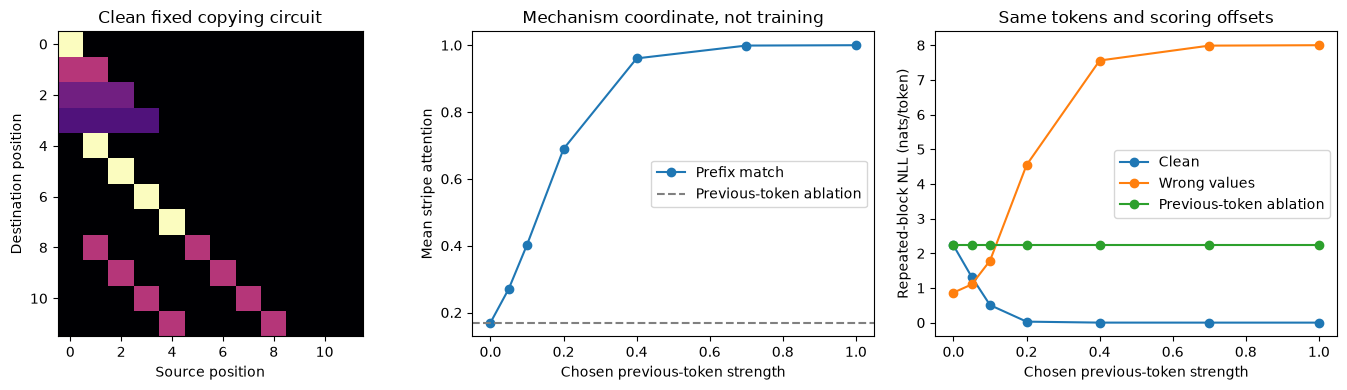

In [ ]:
period = 4
tokens = repeat_tokens(period, 3)
strengths = np.array([0., .05, .1, .2, .4, .7, 1.])
scores, gains, clean_loss, wrong_loss, ablated_loss = [], [], [], [], []
for strength in strengths:
    attn = induction_pattern(tokens, period, strength)
    loss = next_token_loss(copy_logits(attn, tokens, period), tokens)
    wrong = next_token_loss(copy_logits(attn, (tokens+1)%period, period), tokens)
    keys = ablate_previous(prefix_keys(tokens, period, strength))
    ablated = causal_softmax(12 * np.eye(period)[tokens] @ keys.T)
    abl_loss = next_token_loss(copy_logits(ablated, tokens, period), tokens)
    scores.append(prefix_score(attn, period)); gains.append(icl_gain(loss, period))
    clean_loss.append(loss[period:2*period-1].mean())
    wrong_loss.append(wrong[period:2*period-1].mean())
    ablated_loss.append(abl_loss[period:2*period-1].mean())
print("strength prefix repeated_loss wrong_value_loss ablated_loss")
for row in zip(strengths, scores, clean_loss, wrong_loss, ablated_loss):
    print(" ".join(f"{v:.4f}" for v in row))
fig, axes = plt.subplots(1,3,figsize=(14,4))
axes[0].imshow(induction_pattern(tokens,period),vmin=0,vmax=1,cmap="magma")
axes[0].set(title="Clean fixed copying circuit",xlabel="Source position",ylabel="Destination position")
axes[1].plot(strengths,scores,"o-",label="Prefix match")
axes[1].axhline(prefix_score(induction_pattern(tokens,period,0),period),ls="--",color="gray",label="Previous-token ablation")
axes[1].set(title="Mechanism coordinate, not training",xlabel="Chosen previous-token strength",ylabel="Mean stripe attention")
axes[1].legend()
for vals,label in [(clean_loss,"Clean"),(wrong_loss,"Wrong values"),(ablated_loss,"Previous-token ablation")]:
    axes[2].plot(strengths,vals,"o-",label=label)
axes[2].set(title="Same tokens and scoring offsets",xlabel="Chosen previous-token strength",ylabel="Repeated-block NLL (nats/token)")
axes[2].legend(); utils.finish_figure(fig)

<details><summary>Help - how should I interpret this?</summary>

The stripe belongs one position **after** a previous token match. At high strength, the clean values copy the continuation; rotating value IDs leaves attention unchanged but predicts the wrong token. The zero-key control has causal-uniform attention. This separates attending correctly from copying correctly. At strength zero, rotated values happen to improve loss (.8668 versus 2.2255) because numeric token IDs are cyclically ordered: this control is not a universally useless readout. At strength one it has loss 8.0007 versus .0010 for clean copying, so it exposes the specific high-strength mechanism. This low-strength anomaly is a reason to inspect controls across the whole curve.

The horizontal coordinate was chosen by us, so a sharp change here is a property of a nonlinear readout, not evidence of a training phase transition.

</details>

In [ ]:
print("composition scores at strength 0 and 1:",
      composition_score(np.zeros((4,4)),np.eye(4)),
      composition_score(np.eye(4),np.eye(4)))

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">composition scores at strength 0 and 1: 0.0 0.5</pre>

</details>

For every nonzero scalar multiple of the same identity path the normalized score stays .5. Thus this weight diagnostic deliberately does **not** track the strength-dependent behavioral change. In a native transformer use the actual embedding, previous-head OV and later-head QK maps with declared axes; do not infer emergence merely from a normalized map score.

## Summary of 3️⃣

You have a mechanistic sufficiency example and a controlled inference-time lesion. You do not yet have evidence that SGD discovers this circuit or that a loss bump marks its birth.

# 4️⃣ From fixed circuits to training checkpoints

> ##### Learning Objectives
>
> - Design an honest phase-change analysis and edit the repeated-token organism.

<details><summary>Reference measurement</summary>

<pre style="white-space: pre-wrap">period 4, strength 1:
prefix score ≈ 1.0000
repeated-block NLL clean ≈ .0010
repeated-block NLL zero keys ≈ 2.2255
repeated-block NLL rotated values ≈ 8.0007</pre>

</details>

## Try it yourself

Change the period to 6 while keeping the attention temperature fixed. Predict the prefix score and repeated loss first: there are now more nonmatching keys competing for mass. Then try a block containing repeated token IDs; explain why the single-source stripe metric becomes incomplete. Do not tune the threshold until the control looks persuasive.


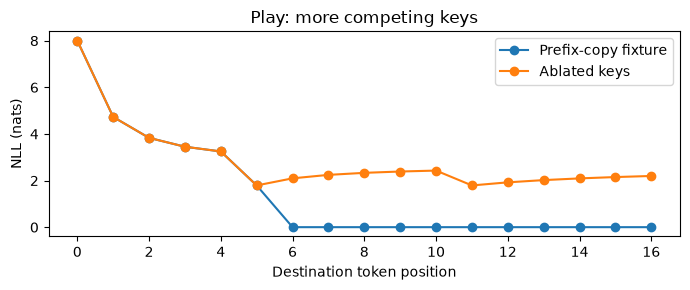

In [ ]:
play_period = 6
play_tokens = repeat_tokens(play_period, 3)
play_attn = induction_pattern(play_tokens, play_period)
play_uniform = induction_pattern(play_tokens, play_period,0)
fig, ax = plt.subplots(figsize=(7,3))
for attn,label in [(play_attn,"Prefix-copy fixture"),(play_uniform,"Ablated keys")]:
    losses = next_token_loss(copy_logits(attn,play_tokens,play_period),play_tokens)
    ax.plot(np.arange(len(losses)),losses,"o-",label=label)
ax.set(xlabel="Destination token position",ylabel="NLL (nats)",title="Play: more competing keys")
ax.legend();utils.finish_figure(fig)
print("prefix score",round(prefix_score(play_attn,play_period),4))

### Native checkpoint bridge

A native adapter must cache **attention probabilities**, the previous-token head’s output, and logits on the same ordered tokens at every checkpoint. Feed these arrays into your visible `prefix_score`, `next_token_loss`, and `icl_gain`; record a matrix path diagnostic separately. Pythia checkpoints provide a source-grounded way to ask whether the same diagnostics co-occur across real optimization time, but a token/revision-matched analysis has not run here.

For the two-layer attention-only training experiment, freeze data, optimizer, seed, checkpoint cadence, smoothing, onset threshold and loss-bump definition before execution. Compare normal training to the predeclared previous-token-head freeze and a matched unrelated-head freeze. Report train loss, repeated-context measurements on monitored DEV, and untouched TEST only if it really stayed unopened. A finite repeated-token fixture is a circuit diagnostic, not language-model generalization.

**Anomaly hunt:** a head has high prefix score but no in-context improvement. Which of keys, values, output projection, scoring offsets or alternate routes would you inspect first? Your wrong-value control is a concrete counterexample to the claim that attention alone establishes function.

## Summary of 4️⃣

You can now state exactly which arrays and counterfactuals the native experiment must supply, without filling the missing evidence with a planted trajectory.

# ☆ Bonus

## Limitations

The organism is a constructed two-stage attention circuit with one-hot keys and values. No optimizer, trained two-layer model, Pythia checkpoint download, full weight-composition analysis or training-time freezing is executed. We establish implementation and causal sufficiency on the public finite sequence, not learned emergence or independent language-model evaluation.

## Further Reading

- [Olsson et al.: In-context Learning and Induction Heads](https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html) — empirical phase changes and induction-circuit evidence.
- [Biderman et al.: Pythia](https://arxiv.org/abs/2304.01373) — controlled public training checkpoints, not measurements loaded by this notebook.
- [ARENA induction circuits](https://arena-chapter1-transformer-interp.streamlit.app/) — model-hook implementation background.